# Single-Stock Risk Report

A parameterized report on one stock's returns and risk, built from the cleaned table `ohlc_hw_cleaned` (Part 1). Run it directly, or with papermill to produce one report per ticker (Part 3).

## Parameters
The cell below is tagged `parameters`, so papermill can replace these values for each run.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy that contains ohlc_hw_cleaned

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


## Setup
Imports, report constants (trading days per year, rolling windows, risk-free rate) and a shared color scheme.

In [3]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

TRADING_DAYS = 252
VOL_WINDOW = 20
MA_WINDOW = 50
RISK_FREE_RATE = 0.02
COLORS = {"up": "#2e9e5b", "down": "#d64545", "neutral": "#8a8a8a",
          "line": "#1f4e79", "ma": "#e08a1e", "dd": "#d64545"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

## Load the data
Read the requested ticker and date range from `ohlc_hw_cleaned` and validate it. The window asked for and the data actually available can differ, so the report shows both. A 20-day volatility needs at least 21 prices (20 returns).

In [4]:
def load_prices(db_path: str, ticker: str, start_date: str, end_date: str) -> pd.DataFrame:
    """Load cleaned daily rows for one ticker and date range, indexed by date.

    Raises FileNotFoundError if the database is missing and ValueError if the
    ticker has no rows in the window or the rows fail basic validation.
    """
    path = Path(db_path)
    if not path.is_file():
        raise FileNotFoundError(f"Database not found: {path.resolve()}")
    query = ("SELECT ts, open, high, low, close, adj_close, volume FROM ohlc_hw_cleaned "
             "WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts")
    with sqlite3.connect(path) as conn:
        df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date))
    if df.empty:
        raise ValueError(f"No cleaned rows for {ticker!r} between {start_date} and {end_date}.")
    df["ts"] = pd.to_datetime(df["ts"], format="%Y-%m-%d")
    df = df.set_index("ts")
    if df.index.duplicated().any():
        raise ValueError(f"{ticker}: duplicate dates in ohlc_hw_cleaned.")
    if not (np.isfinite(df["adj_close"]).all() and df["adj_close"].gt(0).all()):
        raise ValueError(f"{ticker}: non-finite or nonpositive adjusted close.")
    return df

df = load_prices(db_path, ticker, start_date, end_date)
first_obs, last_obs = df.index.min().date(), df.index.max().date()
n_days = len(df)
print(f"{ticker} from {start_date} to {end_date}: {n_days} trading days")
print(f"Actual coverage: {first_obs} to {last_obs}")
if n_days < VOL_WINDOW + 1:
    raise ValueError(f"{ticker}: {n_days} prices give {n_days - 1} returns; "
                     f"a {VOL_WINDOW}-day volatility needs at least {VOL_WINDOW + 1} prices.")
if n_days < MA_WINDOW:
    print(f"Note: only {n_days} prices, so the {MA_WINDOW}-day moving average is unavailable.")
display(df.head(3))
display(df.tail(3))

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual coverage: 2024-06-03 to 2024-11-29


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


## Risk metrics
All metrics are calculated on **adjusted close**, so splits and dividends do not show up as fake price moves. Values are kept as fractions; percentages appear only in printed output.

### Daily log returns
$r_t = \ln(P_t / P_{t-1})$. The first day has no return.

In [5]:
def calculate_returns(prices: pd.Series):
    """Calculate daily log returns, ln(P_t / P_{t-1}).

    `prices` should be one ticker's adjusted close, sorted by date. The first date has no
    previous price, so its return is NaN (a gap, never filled with 0). Nonpositive or
    non-finite prices give NaN instead of -inf, because the log is undefined there.
    """
    valid = prices.where(np.isfinite(prices) & prices.gt(0))
    return np.log(valid / valid.shift(1)).rename("log_return")

returns = calculate_returns(df["adj_close"])
print(f"{returns.notna().sum()} daily log returns from {n_days} prices")
display(returns.describe().to_frame())

125 daily log returns from 126 prices


,log_return
count,125.000000
mean,0.002685
std,0.012861
min,-0.063693
25%,-0.004197
50%,0.002157
75%,0.009398
max,0.042350


### Rolling volatility (20-day)
The standard deviation of the last 20 log returns, annualized with $\sqrt{252}$. The first 20 dates have no estimate (warm-up).

In [6]:
def calculate_volatility(returns: pd.Series, window: int = VOL_WINDOW):
    """Calculate annualized rolling volatility of daily log returns.

    Standard deviation over the last `window` returns, scaled by sqrt(252) to an annual
    figure. The first `window` dates are NaN (warm-up: not enough returns yet); they are
    left as gaps, never filled with 0.
    """
    return (returns.rolling(window).std() * np.sqrt(TRADING_DAYS)).rename("rolling_vol")

rolling_vol = calculate_volatility(returns)
print(f"{rolling_vol.notna().sum()} volatility estimates; first on {rolling_vol.first_valid_index().date()}")
display(rolling_vol.describe().to_frame())

106 volatility estimates; first on 2024-07-02


,rolling_vol
count,106.000000
mean,0.199332
std,0.054699
min,0.114959
25%,0.154464
50%,0.183447
75%,0.245465
max,0.311255


### Drawdown and maximum drawdown
Drawdown is how far the price is below its highest level so far. The maximum drawdown is the worst value over the report.

In [7]:
def calculate_max_drawdown(prices: pd.Series):
    """Return per-date drawdown from the running price peak.

    Drawdown = (price - highest price so far) / highest price so far. It is 0 at a new
    peak and negative below it, and it recovers when the price climbs back. The maximum
    drawdown for the summary is the most negative value, `drawdown.min()`.
    """
    cum_max = prices.cummax()                       # running peak up to each date
    return ((prices - cum_max) / cum_max).rename("drawdown")

drawdown = calculate_max_drawdown(df["adj_close"])
max_dd = drawdown.min()                             # worst peak-to-trough loss
max_dd_date = drawdown.idxmin()
peak_date = df["adj_close"].loc[:max_dd_date].idxmax()
print(f"Maximum drawdown: {max_dd:.2%} on {max_dd_date.date()} (from peak on {peak_date.date()})")
display(drawdown.describe().to_frame())

Maximum drawdown: -12.90% on 2024-10-30 (from peak on 2024-10-14)


,drawdown
count,126.000000
mean,-0.022549
std,0.036449
min,-0.129038
25%,-0.018276
50%,-0.006647
75%,0.000000
max,0.000000


### Sharpe ratio
Excess return per unit of risk: $(\bar r \times 252 - r_f) / (\sigma \times \sqrt{252})$ with a 2% risk-free rate. It is N/A when volatility is zero or there are too few returns.

In [8]:
def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = RISK_FREE_RATE):
    """Calculate annualized Sharpe ratio from daily log returns.

    (annualized mean return - risk-free rate) / annualized volatility, using the course
    approximation mean * 252 and std * sqrt(252). Returns NaN when there are fewer than
    2 returns or the volatility is zero, because the ratio is undefined there.
    """
    r = returns.dropna()                            # skip the first-day / warm-up gap
    if len(r) < 2:
        return np.nan
    std = r.std()
    if not np.isfinite(std) or std == 0:
        return np.nan
    return (r.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))

sharpe = calculate_sharpe_ratio(returns)
print(f"Sharpe ratio (rf = {RISK_FREE_RATE:.0%}): {sharpe:.2f}" if np.isfinite(sharpe)
      else "Sharpe ratio: N/A (not enough returns or zero volatility)")

Sharpe ratio (rf = 2%): 3.22


## Charts
- **Top left:** price colored by volatility regime (red above the report's mean volatility, green at or below it, gray during warm-up), with the 50-day moving average.
- **Top right:** daily log returns.
- **Bottom left:** 20-day rolling volatility against its mean.
- **Bottom right:** drawdown from the running peak, with the maximum drawdown marked.

Coloring by the mean volatility is retrospective: the mean uses the whole report period.

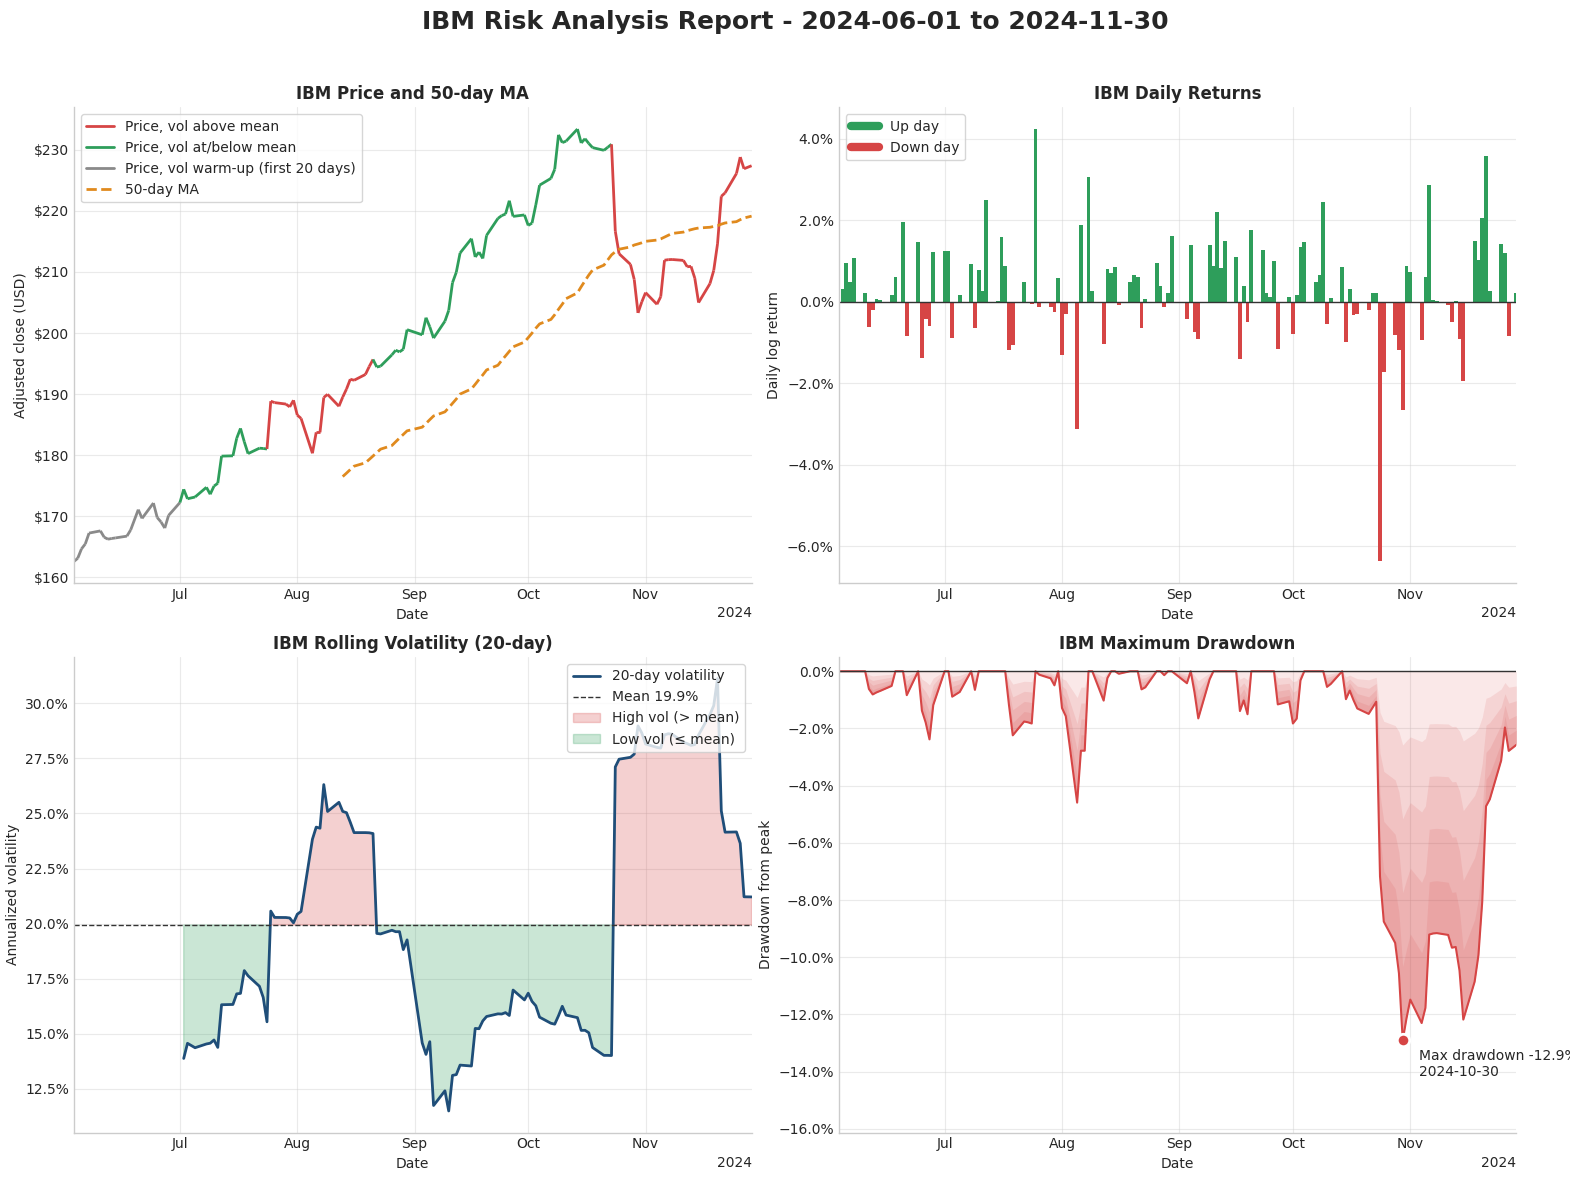

In [9]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, MaxNLocator, PercentFormatter

def plot_risk_report(prices, returns, rolling_vol, drawdown, ticker, start_date, end_date):
    """Draw the 2x2 risk report: price/MA, daily returns, rolling volatility, drawdown.

    All inputs are date-indexed Series in fractions (prices in USD). Warm-up NaNs are kept
    as gaps: gray on the price line, blank on the volatility chart. Returns the figure.
    """
    vol_mean = rolling_vol.mean()                   # report-wide threshold (retrospective)
    ma = prices.rolling(MA_WINDOW).mean()           # NaN until MA_WINDOW prices exist
    hi_c, lo_c, na_c = COLORS["down"], COLORS["up"], COLORS["neutral"]

    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        ax_p, ax_r, ax_v, ax_d = axes.flat

        # Top left: price line colored by that day's rolling volatility vs the mean
        x = mdates.date2num(prices.index)
        pts = np.column_stack([x, prices.to_numpy()])
        segments = np.stack([pts[:-1], pts[1:]], axis=1)          # one segment per day
        seg_vol = rolling_vol.reindex(prices.index).to_numpy()[1:]  # vol at segment end
        seg_colors = np.where(np.isnan(seg_vol), na_c, np.where(seg_vol > vol_mean, hi_c, lo_c))
        ax_p.add_collection(LineCollection(segments, colors=seg_colors, linewidths=2))
        ax_p.autoscale_view()
        handles = [Line2D([], [], color=hi_c, lw=2, label="Price, vol above mean"),
                   Line2D([], [], color=lo_c, lw=2, label="Price, vol at/below mean"),
                   Line2D([], [], color=na_c, lw=2, label=f"Price, vol warm-up (first {VOL_WINDOW} days)")]
        if ma.notna().any():
            ax_p.plot(ma.index, ma, color=COLORS["ma"], lw=2, ls="--")
            handles.append(Line2D([], [], color=COLORS["ma"], lw=2, ls="--", label=f"{MA_WINDOW}-day MA"))
        else:
            ax_p.text(0.02, 0.04, f"{MA_WINDOW}-day MA unavailable: only {len(prices)} prices",
                      transform=ax_p.transAxes, color=na_c, fontsize=10)
        ax_p.legend(handles=handles, loc="upper left", frameon=True)
        ax_p.yaxis.set_major_locator(MaxNLocator(steps=[1, 2, 5, 10]))   # whole-dollar steps
        ax_p.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
        ax_p.set(title=f"{ticker} Price and {MA_WINDOW}-day MA", ylabel="Adjusted close (USD)")

        # Top right: daily log returns, green up / red down
        r = returns.dropna()
        ax_r.bar(r.index, r, width=1.0, color=np.where(r >= 0, lo_c, hi_c), linewidth=0)
        ax_r.axhline(0, color="#333333", lw=1)
        ax_r.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax_r.legend(handles=[Line2D([], [], color=lo_c, lw=6, label="Up day"),
                             Line2D([], [], color=hi_c, lw=6, label="Down day")],
                    loc="upper left", frameon=True)
        ax_r.set(title=f"{ticker} Daily Returns", ylabel="Daily log return")

        # Bottom left: rolling volatility vs its mean, shaded above/below
        ax_v.plot(rolling_vol.index, rolling_vol, color=COLORS["line"], lw=2, label=f"{VOL_WINDOW}-day volatility")
        ax_v.axhline(vol_mean, color="#333333", lw=1, ls="--", label=f"Mean {vol_mean:.1%}")
        ax_v.fill_between(rolling_vol.index, rolling_vol, vol_mean, where=rolling_vol > vol_mean,
                          interpolate=True, color=hi_c, alpha=0.25, label="High vol (> mean)")
        ax_v.fill_between(rolling_vol.index, rolling_vol, vol_mean, where=rolling_vol <= vol_mean,
                          interpolate=True, color=lo_c, alpha=0.25, label="Low vol (≤ mean)")
        ax_v.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax_v.legend(loc="upper right", frameon=True)
        ax_v.set(title=f"{ticker} Rolling Volatility ({VOL_WINDOW}-day)", ylabel="Annualized volatility")

        # Bottom right: drawdown area; layered transparent fills darken toward the trough
        for k in np.linspace(0, 0.8, 5):
            ax_d.fill_between(drawdown.index, drawdown, drawdown * k, color=COLORS["dd"], alpha=0.12, lw=0)
        ax_d.plot(drawdown.index, drawdown, color=COLORS["dd"], lw=1.5)
        ax_d.axhline(0, color="#333333", lw=1)
        dd_date, dd_val = drawdown.idxmin(), drawdown.min()
        ax_d.scatter([dd_date], [dd_val], s=80, color=COLORS["dd"], edgecolor="white", lw=2, zorder=3)
        ax_d.annotate(f"Max drawdown {dd_val:.1%}\n{dd_date:%Y-%m-%d}", (dd_date, dd_val),
                      xytext=(12, -6), textcoords="offset points", va="top", fontsize=10)
        ax_d.set_ylim(min(dd_val * 1.25, -0.01), 0.005)
        ax_d.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax_d.set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown from peak")

        # Shared formatting: same date range and concise date ticks on every panel
        locator = mdates.AutoDateLocator()
        for ax in axes.flat:
            ax.set_xlim(prices.index.min(), prices.index.max())
            ax.xaxis.set_major_locator(locator)
            ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
            ax.set_xlabel("Date")
            ax.grid(True, alpha=0.4)
            ax.title.set_fontweight("bold")

        fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}",
                     fontsize=18, fontweight="bold")
        fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig

fig = plot_risk_report(df["adj_close"], returns, rolling_vol, drawdown, ticker, start_date, end_date)
plt.show()

## Summary statistics
Whole-period figures. Total return uses adjusted close; the rest use daily log returns. Positive days count zero-return days in the total, and an empty up/down subset shows N/A.

In [10]:
def summary_metrics(prices: pd.Series, returns: pd.Series, drawdown: pd.Series):
    """Whole-period summary statistics, all as fractions (NaN when undefined).

    Total return uses adjusted close; everything else uses daily log returns. Positive days
    are positive returns divided by ALL nonmissing returns (zero days count in the total).
    """
    r = returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return pd.Series({
        "Total Return":          prices.iloc[-1] / prices.iloc[0] - 1,
        "Annualized Return":     np.exp(r.sum() * TRADING_DAYS / n) - 1 if n else np.nan,
        "Annualized Volatility": r.std() * np.sqrt(TRADING_DAYS) if n > 1 else np.nan,
        "Sharpe Ratio":          calculate_sharpe_ratio(returns),
        "Maximum Drawdown":      drawdown.min(),
        "Best Day":              r.max() if n else np.nan,
        "Worst Day":             r.min() if n else np.nan,
        "Positive Days":         len(up) / n if n else np.nan,
        "Average Up Day":        up.mean() if len(up) else np.nan,     # empty subset -> N/A
        "Average Down Day":      down.mean() if len(down) else np.nan,
    }, name="value")

# Display format per metric: signed %, unsigned %, or plain number. NaN shows as N/A.
FORMATS = {"Annualized Volatility": "{:.2%}", "Positive Days": "{:.1%}", "Sharpe Ratio": "{:.2f}"}

def format_summary(metrics: pd.Series):
    """Turn fractions into display strings (percentages only here, never in the data)."""
    return pd.Series({m: "N/A" if pd.isna(v) else FORMATS.get(m, "{:+.2%}").format(v)
                      for m, v in metrics.items()})

summary = summary_metrics(df["adj_close"], returns, drawdown)    # fractions, for reuse
print(f"{ticker} summary, {first_obs} to {last_obs} ({n_days} trading days)\n")
print(f"{'Metric':<24}  {'Value':>8}\n{'-' * 24}  {'-' * 8}")
for metric, value in format_summary(summary).items():
    print(f"{metric:<24}  {value:>8}")

IBM summary, 2024-06-03 to 2024-11-29 (126 trading days)

Metric                       Value
------------------------  --------
Total Return               +39.88%
Annualized Return          +96.73%
Annualized Volatility       20.42%
Sharpe Ratio                  3.22
Maximum Drawdown           -12.90%
Best Day                    +4.24%
Worst Day                   -6.37%
Positive Days                63.2%
Average Up Day              +0.95%
Average Down Day            -0.92%


## Named outputs for the batch run
Record the key results with scrapbook so `03_run_all_stocks.py` can collect them from each executed report. Values are fractions; coverage dates show the data actually available.

In [11]:
# Named outputs read by 03_run_all_stocks.py (fractions; NaN where undefined)
sb.glue("ticker", ticker)
sb.glue("first_obs", str(first_obs))
sb.glue("last_obs", str(last_obs))
sb.glue("n_days", int(n_days))
sb.glue("avg_daily_return", float(returns.mean()))      # mean daily log return
sb.glue("avg_volatility", float(rolling_vol.mean()))    # mean of 20-day rolling volatility
sb.glue("max_drawdown", float(summary["Maximum Drawdown"]))
sb.glue("sharpe_ratio", float(summary["Sharpe Ratio"]))
sb.glue("total_return", float(summary["Total Return"]))